# 🧪 Teste A/B da campanha de marketing

**Autor:** Rafael R. Silva · **Projeto:** Segmentação de Clientes com K-Means · **Tema:** Teste A/B, A/B/n, Bayesiano e Multi-Armed Bandit

> **Resumo:** a segmentação (notebook v2) disse **quem priorizar** na campanha. Este notebook responde à pergunta seguinte: **a priorização funciona mesmo?** Aplicamos ao projeto os 4 tipos de teste do curso de Teste A/B, em 4 ciclos, e terminamos com o teste ideal para o caso e como colocá-lo em produção.

---

### 📑 Sumário
- **Abertura:** o problema, a conta do lucro e como os experimentos foram montados
- **Ciclo 01:** Teste A-B
- **Ciclo 02:** Teste A-B-n
- **Ciclo 03:** Teste A-B Bayesiano
- **Ciclo 04:** MAB (Multi-Armed Bandit)
- **Conclusão:** o teste ideal e a aplicação em produção

## 🏢 O problema de negócio

A empresa vai mandar uma campanha de marketing. Cada contato **custa 3** e cada cliente que aceita a oferta **traz 11** de receita (colunas `Z_CostContact` e `Z_Revenue` da base).

A segmentação recomendou **priorizar o segmento Premium e, em seguida, os Fiéis de alto volume** (README, seção de resultados). Mas uma recomendação é uma **hipótese**: só um experimento mostra se ela dá resultado.

> **Pergunta de negócio:** *para quem devemos mandar a campanha para ter o maior retorno?*

### O que é um Teste A/B, em uma frase
Dividimos os clientes **por sorteio** em grupos, cada grupo recebe uma versão diferente (A, B…), e medimos se a diferença no resultado é **real** ou só **sorte do sorteio**.

```
              clientes
                 │
           ┌─ sorteio ─┐          o sorteio deixa os grupos parecidos:
           ▼           ▼          a única diferença entre eles é a versão
       Grupo A      Grupo B
      (controle)  (tratamento)
           │           │
           ▼           ▼
       resultado   resultado  ──► a diferença é real ou foi sorte?
```

### Os 5 passos de todo teste (iguais nos 4 ciclos)
| Passo | O que fazemos |
|---|---|
| **1. Escolha do método** | Qual teste responde à pergunta (A/B, A/B/n, Bayesiano, MAB)? |
| **2. Design do experimento** | Hipóteses, métrica, grupos, nível de significância e tamanho da amostra |
| **3. Coleta e preparação dos dados** | Sortear, conferir se o sorteio saiu certo, montar a tabela |
| **4. Teste das hipóteses** | Aplicar o teste estatístico |
| **5. Conclusões** | Traduzir o resultado para o negócio |

## 1 - Bibliotecas e funções

In [1]:
import sys
import pickle

import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt
from scipy import stats

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.graficos import salvar
from src.teste_ab import (CUSTO_CONTATO, RECEITA_RESPOSTA, PONTO_EQUILIBRIO, CORES,
                          limpar_base, segmentar, lucro, sortear_grupos, teste_srm,
                          tamanho_amostra_proporcoes, tamanho_amostra_qui_quadrado,
                          teste_z_proporcoes, post_hoc_bonferroni, comparar_bayesiano,
                          AgenteAleatorio, AgenteOnisciente, AgenteGuloso, AgenteEpsilonGuloso,
                          AgenteThompson, simular_bandit, poder_simulado_qui_quadrado)
from src.estatistica import teste_kruskal

As funções ficam em **`src/teste_ab.py`**:

| Função | Para que serve |
|---|---|
| `limpar_base`, `segmentar` | Repetem a limpeza do notebook v2 e dão o segmento de cada cliente pelo modelo salvo |
| `lucro` | Lucro de cada cliente: 11 se respondeu, menos 3 se foi contatado |
| `sortear_grupos`, `teste_srm` | Sorteio dos grupos e checagem de que o sorteio saiu certo |
| `tamanho_amostra_proporcoes`, `tamanho_amostra_qui_quadrado` | Quantos contatos cada grupo precisa |
| `teste_z_proporcoes`, `post_hoc_bonferroni` | Testes frequentistas dos Ciclos 01 e 02 |
| `comparar_bayesiano` | Probabilidade de B ser melhor, perda esperada e chance de dar lucro (Ciclo 03) |
| `Agente...`, `simular_bandit` | Os 5 agentes do Multi-Armed Bandit (Ciclo 04) |

## 2 - A conta do lucro: o ponto de equilíbrio

Antes de qualquer teste, uma conta simples: **a partir de que taxa de resposta o contato se paga?**

Se uma fração *t* dos contatados responde, cada contato traz em média `11 × t − 3`. O contato só dá lucro quando `11 × t > 3`, ou seja, quando **t > 3 / 11**.

In [2]:
print(f'Custo por contato: {CUSTO_CONTATO} | Receita por resposta: {RECEITA_RESPOSTA}')
print(f'Ponto de equilíbrio: {PONTO_EQUILIBRIO:.1%} de resposta')

Custo por contato: 3 | Receita por resposta: 11
Ponto de equilíbrio: 27.3% de resposta


📌 **Nota**
- 🔎 Cada contato só se paga se pelo menos **27,3%** dos contatados aceitarem a oferta.
- 💡 Esse número é a régua de todo o notebook: uma regra de contato com taxa abaixo de 27,3% **perde dinheiro**, por melhor que pareça.

## 3 - Os dados e o segmento de cada cliente

Usamos a mesma base e a mesma limpeza do notebook v2, e o **modelo salvo na Fase 05** dá o segmento de cada cliente.

### 🛡️ Cuidado com vazamento
No notebook v2, a variável `AcceptedCmp` soma as 6 campanhas, **incluindo a última** (`Response`), que é justamente o resultado que vamos medir. Se o segmento usasse a resposta para escolher quem recebe a campanha, o teste ficaria "viciado".

✅ **Decisão:** recalcular o segmento só com o histórico de **antes** da campanha (campanhas 1 a 5) e comparar com o original.

In [3]:
modelo = pickle.load(open('../Model/pipeline_segmentacao.pkl', 'rb'))
df = limpar_base(pd.read_csv('../Datasets/marketing_campaign.csv', delimiter='\t'))

segmento_original = segmentar(df, modelo, com_resposta=True)   # como no notebook v2
df['segmento'] = segmentar(df, modelo, com_resposta=False)      # só com o histórico de antes da campanha

print(f'Clientes: {len(df):,}')
print('Segmentos (como no v2):', segmento_original.value_counts().to_dict())
print('Segmentos (sem a resposta):', df['segmento'].value_counts().to_dict())
print(f'Clientes que mudam de segmento: {(segmento_original != df["segmento"]).sum()}')

Clientes: 2,203
Segmentos (como no v2): {'Fiéis de alto volume': 629, 'Novos e ativos': 587, 'Em risco de churn': 568, 'Premium': 419}
Segmentos (sem a resposta): {'Fiéis de alto volume': 631, 'Novos e ativos': 587, 'Em risco de churn': 568, 'Premium': 417}
Clientes que mudam de segmento: 2


📌 **Nota**
- 🔎 Sem a resposta da última campanha, só **2 clientes** mudam de segmento: o Premium passa de 419 para **417** clientes e os Fiéis, de 629 para **631**.
- ✅ O vazamento era pequeno, mas agora está eliminado: o segmento usado nos testes só conhece o que aconteceu **antes** da campanha.

### Como os experimentos foram montados (replay com respostas reais)

A última campanha foi enviada a **todos** os clientes, então sabemos a resposta **verdadeira** de cada um. Isso permite **reconstruir** cada experimento sem inventar números:

```
 1. sorteio ──► cada cliente cai num grupo (A, B, ...)
 2. regra   ──► cada grupo tem sua regra de contato (ex.: "só Premium")
 3. leitura ──► para quem foi contatado, usamos a resposta REAL da base
                para quem não foi contatado: sem custo e sem receita
```

⚠️ **Premissas:** (1) a oferta é a mesma para todos; (2) a resposta de um cliente não depende de quem mais foi contatado. Num experimento de verdade, os grupos seriam contatados em paralelo, no mesmo período.

In [4]:
ORDEM = ['Premium', 'Fiéis de alto volume', 'Novos e ativos', 'Em risco de churn']  # a cor segue o segmento

taxas_segmento = (df.groupby('segmento')['Response'].agg(clientes='size', respostas='sum', taxa='mean')
                    .loc[ORDEM])
taxas_segmento['lucro por contato'] = RECEITA_RESPOSTA * taxas_segmento['taxa'] - CUSTO_CONTATO
taxas_segmento

,clientes,respostas,taxa,lucro por contato
segmento,,,,
Premium,417,140,0.3357,0.6930
Fiéis de alto volume,631,78,0.1236,-1.6403
Novos e ativos,587,90,0.1533,-1.3135
Em risco de churn,568,24,0.0423,-2.5352


In [5]:
print(f'Taxa de resposta na base inteira: {df["Response"].mean():.1%}')
print(f'Lucro se a campanha for para todos: {lucro(df["Response"], 1).sum():,}')

Taxa de resposta na base inteira: 15.1%
Lucro se a campanha for para todos: -2,957


📌 **Nota**
- 🔎 Mandar a campanha para **todos** dá taxa de **15,1%** e um prejuízo de **2.957**.
- 🔎 Por segmento, só o **Premium** passa do ponto de equilíbrio: **33,6%** de resposta e lucro de **+0,69** por contato. Novos e ativos (**15,3%**), Fiéis (**12,4%**) e Em risco (**4,2%**) perdem de **1,31** a **2,54** por contato.
- ⚠️ Essa tabela é uma **foto** da base inteira, não um experimento. Os ciclos a seguir mostram como **provar** essas diferenças com um teste, como seria feito antes de mudar a campanha.

# Ciclo 01 - Teste A-B

> **Pergunta:** *a recomendação da segmentação (mandar só para Premium + Fiéis) é melhor do que mandar para todos?*

## Passo 1 - Escolha do método
São **duas versões** de uma regra de contato e queremos saber se a nova é melhor que a atual: é o caso clássico de um **Teste A/B**.

Qual teste estatístico usar? Seguimos o **mapa de escolha do curso** (Aula 9):

```
 taxa de resposta ── dado categórico (respondeu / não respondeu), n > 5
                      └─► dois grupos: teste Z  (ou qui-quadrado, que dá o mesmo resultado)

 lucro por cliente ── dado contínuo ─► diferença de médias ─► dois grupos
                      └─► suposições paramétricas satisfeitas?  não ─► Mann-Whitney (ou Welch)
```

> 📚 **No curso:** Aula 2 (os 5 passos), Aulas 5 e 6 (hipóteses, α, poder, Cohen's h e `NormalIndPower`), Aula 8 (efeito mínimo), Aula 9 (mapa de escolha do teste), Aulas 10 e 11 (Mann-Whitney e Welch), notebooks **PA James** (conversão) e **PA Bond** (média de gasto).

## Passo 2 - Design do experimento

| Item | Definição |
|---|---|
| **Grupo A (controle)** | Recebe a campanha como hoje: **todos** os clientes são contatados |
| **Grupo B (tratamento)** | Só os clientes **Premium e Fiéis de alto volume** são contatados |
| **Divisão** | Sorteio, metade para cada grupo |
| **Métrica 1: taxa de resposta** | Respostas ÷ contatos (a conversão da campanha) |
| **Métrica 2: lucro por cliente** | (11 × respostas − 3 × contatos) ÷ clientes do grupo, a métrica do negócio |

**Hipóteses (teste bicaudal, como no curso):**
- **H0:** a taxa de resposta de B é igual à de A (a diferença é só sorte do sorteio).
- **H1:** a taxa de resposta de B é diferente da de A.

**Parâmetros:**
- **Nível de significância (α) = 5%:** a chance que aceitamos de ver uma diferença que não existe (erro tipo 1).
- **Poder = 80%:** a chance de enxergar a diferença quando ela existe de verdade.
- **Efeito mínimo que vale a pena:** subir a taxa de **15% para 20%** (+5 pontos). Quanto **menor** o efeito que queremos enxergar, **mais** contatos o teste precisa.

💡 A Aula 8 ensina duas maneiras de definir o efeito mínimo: (1) a meta do time de negócio ou (2) o **custo**, isto é, o menor efeito que paga a mudança. Aqui usamos a primeira (+5 pontos). A segunda é o **ponto de equilíbrio de 27,3%**: é ele que diz se uma regra se paga, por isso aparece em todos os gráficos.

In [6]:
alpha, poder = 0.05, 0.80
n_contatos, h = tamanho_amostra_proporcoes(p_controle=0.15, p_tratamento=0.20, alpha=alpha, poder=poder)
print(f"Tamanho do efeito (Cohen's h): {h:.3f}")
print(f'Contatos necessários em cada grupo: {n_contatos:,}')

# Conferência com o curso: o PA James planejou 13% -> 15% e chegou a 4.720 por grupo
print(f'Conferência (PA James, 13% -> 15%): {tamanho_amostra_proporcoes(0.13, 0.15)[0]:,} por grupo')

Tamanho do efeito (Cohen's h): 0.132
Contatos necessários em cada grupo: 903


Conferência (PA James, 13% -> 15%): 4,720 por grupo


📌 **Nota**
- 🔎 Para enxergar uma subida de 15% para 20% com 80% de poder, cada grupo precisa de **903 contatos**.
- ⚠️ O grupo B só contata Premium + Fiéis (cerca de metade dos clientes). Com a base inteira dividida em dois, B terá menos contatos que isso. **O teste da taxa já começa com pouco poder**: se a diferença real for pequena, ele pode não enxergá-la. Saber disso **antes** é exatamente para que serve o cálculo do tamanho da amostra.

## Passo 3 - Coleta e preparação dos dados

### 3.1. Sorteio dos grupos

In [7]:
ciclo1 = df[['ID', 'segmento', 'Income', 'Response']].copy()
ciclo1['grupo'] = sortear_grupos(len(ciclo1), ['A', 'B'], semente=42)

# Regra de contato de cada grupo
ciclo1['contatado'] = np.where(ciclo1['grupo'] == 'A', 1,
                               ciclo1['segmento'].isin(['Premium', 'Fiéis de alto volume']).astype(int))
ciclo1['lucro'] = lucro(ciclo1['Response'], ciclo1['contatado'])

ciclo1.groupby('grupo').agg(clientes=('ID', 'size'), contatos=('contatado', 'sum'))

,clientes,contatos
grupo,,
A,1102,1102
B,1101,530


### 3.2. Checagens do experimento (como no curso)
1. **Unidade experimental:** nenhum cliente pode estar nos dois grupos.
2. **Divisão certa (SRM, *Sample Ratio Mismatch*):** a divisão saiu perto de 50/50? Um p-valor baixo indicaria problema no sorteio.
3. **Homogeneidade:** os dois grupos têm o mesmo perfil (segmentos e renda)?

In [8]:
print('Clientes em mais de um grupo:', (ciclo1.groupby('ID')['grupo'].nunique() > 1).sum())
print(f"SRM p-valor: {teste_srm(ciclo1['grupo'].value_counts().to_numpy()):.3f}")

Clientes em mais de um grupo: 0
SRM p-valor: 0.983


In [9]:
homogeneidade = pd.crosstab(ciclo1['segmento'], ciclo1['grupo'], normalize='columns').loc[ORDEM]
homogeneidade.loc['Renda média (US$)'] = ciclo1.groupby('grupo')['Income'].mean()
homogeneidade

grupo,A,B
segmento,,
Premium,0.1897,0.1889
Fiéis de alto volume,0.2804,0.2925
Novos e ativos,0.2704,0.2625
Em risco de churn,0.2595,0.2561
Renda média (US$),"52,354.7450","51,553.3488"


📌 **Nota**
- 🔎 Nenhum cliente está nos dois grupos, e a divisão saiu equilibrada (**1.102** × **1.101**; SRM p-valor de **0,983**, sem sinal de problema no sorteio).
- 🔎 Os grupos têm o mesmo perfil: o Premium é **19,0%** do grupo A e **18,9%** do B, e a renda média é de **US$ 52.355** × **US$ 51.553**.
- ✅ O sorteio fez o seu trabalho: a única diferença entre os grupos é a regra de contato. O grupo B contatou **530** clientes, abaixo dos **903** planejados.

## Passo 4 - Teste das hipóteses

### 4.1. Taxa de resposta (teste z de duas proporções)
O teste z compara duas **proporções**. Ele dá o mesmo resultado do **qui-quadrado** de uma tabela 2 × 2, usado no curso (conferido abaixo).

In [10]:
contatados1 = ciclo1[ciclo1['contatado'] == 1].groupby('grupo')['Response'].agg(respostas='sum', contatos='count')
contatados1['taxa'] = contatados1['respostas'] / contatados1['contatos']
contatados1

,respostas,contatos,taxa
grupo,,,
A,180,1102,0.1633
B,102,530,0.1925


In [11]:
resultado_z = teste_z_proporcoes(contatados1['respostas'].to_numpy(), contatados1['contatos'].to_numpy())
pd.Series(resultado_z).to_frame('Ciclo 01')

,Ciclo 01
taxa A,0.1633
taxa B,0.1925
diferença (B - A),0.0291
IC 95% inferior,-0.0097
IC 95% superior,0.0704
z,1.4568
p-valor,0.1452


In [12]:
tabela_2x2 = pd.DataFrame({'respondeu': contatados1['respostas'],
                           'não respondeu': contatados1['contatos'] - contatados1['respostas']})
print(f'Qui-quadrado (sem correção de continuidade) p-valor: {stats.chi2_contingency(tabela_2x2, correction=False)[1]:.4f}')
print('Rejeita H0' if resultado_z['p-valor'] < alpha else 'Não rejeita H0: não há evidência de que a taxa de B seja diferente')

Qui-quadrado (sem correção de continuidade) p-valor: 0.1452
Não rejeita H0: não há evidência de que a taxa de B seja diferente


📌 **Nota**
- 🔎 Taxa de resposta: **16,3%** no A (180 de 1.102) × **19,2%** no B (102 de 530), uma diferença de **+2,9 pontos**.
- 🔎 O p-valor é **0,145**, maior que 5%, e o intervalo de 95% da diferença vai de **−1,0 a +7,0 pontos**: ele inclui o zero. O qui-quadrado dá o mesmo p-valor (**0,1452**).
- ✅ **Não rejeitamos H0:** com 530 contatos no B, não há evidência de que a taxa de B seja diferente da de A.
- 💡 "Não rejeitar" **não** é provar que são iguais. Com os 903 contatos planejados, uma diferença desse tamanho talvez aparecesse.

### 4.2. Lucro por cliente (teste t de Welch, como no PA Bond)
Aqui a métrica é uma **média** (lucro por cliente do grupo, contando como 0 quem não foi contatado). Pelo mapa do curso, com dois grupos o teste seria o **t de duas amostras**, mas ele exige as **suposições paramétricas** (dados normais e variâncias iguais). O lucro de um cliente só assume **3 valores** (−3, 0 ou +8), então ele está longe de ser normal. Nesse caso, a Aula 10 indica o **Mann-Whitney** ou o **teste de Welch**: usamos os dois, e eles precisam concordar.

In [13]:
lucro_a = ciclo1.loc[ciclo1['grupo'] == 'A', 'lucro']
lucro_b = ciclo1.loc[ciclo1['grupo'] == 'B', 'lucro']

print(f'Lucro por cliente - A: {lucro_a.mean():.2f} | B: {lucro_b.mean():.2f}')
print(f'Lucro total       - A: {lucro_a.sum():,} | B: {lucro_b.sum():,}')
print(f'Teste t de Welch p-valor: {stats.ttest_ind(lucro_b, lucro_a, equal_var=False).pvalue:.2e}')
print(f'Mann-Whitney p-valor:     {stats.mannwhitneyu(lucro_b, lucro_a).pvalue:.2e}')

Lucro por cliente - A: -1.20 | B: -0.43
Lucro total       - A: -1,326 | B: -468
Teste t de Welch p-valor: 4.02e-07
Mann-Whitney p-valor:     4.17e-65


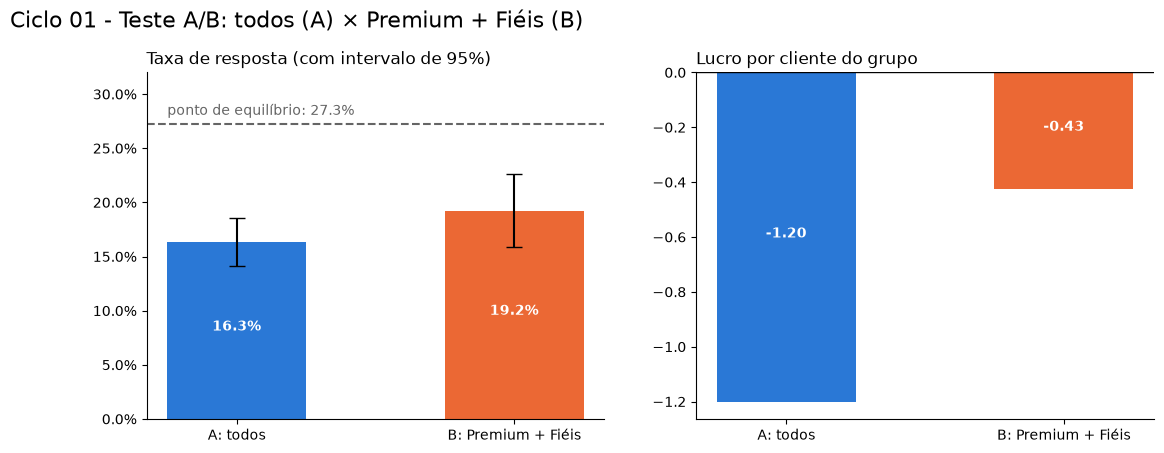

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
plt.suptitle('Ciclo 01 - Teste A/B: todos (A) × Premium + Fiéis (B)', fontsize=16, x=0.02, ha='left', y=1.02)

# Taxa de resposta com o intervalo de 95% de cada grupo
erro = 1.96 * np.sqrt(contatados1['taxa'] * (1 - contatados1['taxa']) / contatados1['contatos'])
eixos[0].bar(['A: todos', 'B: Premium + Fiéis'], contatados1['taxa'], yerr=erro, color=CORES[:2],
             width=0.5, capsize=6)
eixos[0].axhline(PONTO_EQUILIBRIO, color='#656565', ls='--', lw=1.5)
eixos[0].text(-0.25, PONTO_EQUILIBRIO + 0.005, f'ponto de equilíbrio: {PONTO_EQUILIBRIO:.1%}', va='bottom', color='#656565')
eixos[0].set_ylim(0, 0.32)
for i, taxa in enumerate(contatados1['taxa']):
    eixos[0].text(i, taxa / 2, f'{taxa:.1%}', ha='center', color='white', fontweight='bold')
eixos[0].set_title('Taxa de resposta (com intervalo de 95%)', loc='left')
eixos[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))

# Lucro por cliente do grupo
medias = [lucro_a.mean(), lucro_b.mean()]
eixos[1].bar(['A: todos', 'B: Premium + Fiéis'], medias, color=CORES[:2], width=0.5)
eixos[1].axhline(0, color='black', lw=1)
for i, valor in enumerate(medias):
    eixos[1].text(i, valor / 2, f'{valor:.2f}', ha='center', color='white', fontweight='bold')
eixos[1].set_title('Lucro por cliente do grupo', loc='left')

for eixo in eixos:
    eixo.spines[['top', 'right']].set_visible(False)
salvar('Teste AB - Ciclo 01')
plt.show()

📌 **Nota**
- 🔎 Lucro por cliente: **−1,20** no A × **−0,43** no B (total de **−1.326** × **−468**).
- 🔎 Aqui a diferença é clara: teste t de Welch com p-valor de **4,02e-07**, confirmado pelo Mann-Whitney (**4,17e-65**).
- 💡 Por que o lucro mostra diferença e a taxa não? Porque o ganho do B vem principalmente de **não gastar** com quem quase não responde (ele contata 530 clientes em vez de 1.102), e não de uma taxa muito maior.
- ⚠️ No gráfico, as duas barras de taxa ficam **abaixo** da linha de 27,3%: as duas regras perdem dinheiro.

## Passo 5 - Conclusões

📌 **Nota**
- ✅ **Para o negócio:** a regra B (Premium + Fiéis) **perde menos dinheiro** que mandar para todos, e essa diferença é estatisticamente clara. Mas ela **continua no prejuízo**, então não é a resposta final.
- 💡 **Lições do Ciclo 01:**
  1. **Escolher a métrica certa:** a taxa de resposta não mostrou diferença; o lucro, que é o que o negócio quer, mostrou.
  2. **Planejar o tamanho da amostra antes:** o cálculo avisou que o B teria contatos de menos para enxergar diferenças pequenas na taxa.
  3. **Um teste responde só à pergunta que fizemos:** "B é melhor que A?" (sim, no lucro). Ele não diz se existe uma regra **ainda melhor**. Essa é a pergunta do Ciclo 02.

### Quanto isso vale em dinheiro? (como o *lift* do PA James)
Se a regra de cada grupo fosse aplicada à base inteira (2.203 clientes), usando a taxa medida em cada grupo:

In [15]:
clientes_total = len(df)
contatos_b_base = df['segmento'].isin(['Premium', 'Fiéis de alto volume']).sum()

projecao = pd.DataFrame({
    'contatos': [clientes_total, contatos_b_base],
    'taxa medida': contatados1['taxa'].to_numpy()}, index=['A: todos', 'B: Premium + Fiéis'])
projecao['respostas esperadas'] = projecao['contatos'] * projecao['taxa medida']
projecao['lucro esperado'] = RECEITA_RESPOSTA * projecao['respostas esperadas'] - CUSTO_CONTATO * projecao['contatos']
projecao

,contatos,taxa medida,respostas esperadas,lucro esperado
A: todos,2203,0.1633,359.8367,"-2,650.7967"
B: Premium + Fiéis,1048,0.1925,201.6906,-925.4038


📌 **Nota**
- 🔎 Aplicada à base inteira, a regra A (**2.203** contatos) daria um lucro esperado de **−2.651**, e a regra B (**1.048** contatos), de **−925**.
- 💡 A regra B evita a maior parte do prejuízo, mas nenhuma das duas dá lucro: falta testar regras mais seletivas.

# Ciclo 02 - Teste A-B-n

> **Pergunta:** *entre várias regras de contato, qual dá o maior retorno?*

O Ciclo 01 mostrou que a regra B dá prejuízo menor que A, mas **continua no prejuízo**. Então a pergunta muda: em vez de "B é melhor que A?", queremos testar **várias regras ao mesmo tempo**.

## Passo 1 - Escolha do método
Com **mais de duas versões**, usamos o **Teste A/B/n**: o mesmo formato do A/B, com um grupo controle e várias variações.

```
                         clientes
                            │
        ┌──────────────┬── sorteio ──┬────────────────────┐
        ▼              ▼             ▼                    ▼
    A: todos     B: Premium +    C: só Premium    D: todos menos
   (controle)       Fiéis                           Em risco
```

Por que não fazer vários testes A/B separados? Porque **cada teste tem 5% de chance de um falso alarme**. Com 6 comparações, a chance de pelo menos um falso alarme sobe para cerca de **26%** (1 − 0,95⁶). Por isso o A/B/n tem duas etapas:
1. **Qui-quadrado geral:** existe alguma diferença entre as regras?
2. **Post-hoc par a par com correção de Bonferroni:** se existe, **onde** ela está? (cada p-valor é multiplicado pelo número de comparações)

Pelo mapa do curso, a **taxa** (categórica, mais de dois grupos) vai para o **qui-quadrado**. O **lucro** (contínuo, mais de dois grupos, sem as suposições paramétricas) vai para o **Kruskal-Wallis**, a versão sem suposições da ANOVA.

> 📚 **No curso:** Aula 15 (planejamento: qui-quadrado + post-hoc), Aula 17 (erro alfa acumulado α* = 1 − (1 − α)ⁿ e correção de Bonferroni), Aula 19 (tamanho da amostra pelo w de Cohen), Aulas 20 a 22 (qui-quadrado de independência, ANOVA e Kruskal-Wallis), Aula 11 (Kruskal-Wallis), notebook **PA James ABN**.

## Passo 2 - Design do experimento
- **H0:** as 4 regras têm a mesma taxa de resposta.
- **H1:** pelo menos uma regra tem taxa diferente.
- **Métricas:** taxa de resposta (qui-quadrado) e lucro (a decisão de negócio).
- **α = 5%**, **poder = 80%**.
- **Divisão:** sorteio em 4 partes iguais.

In [16]:
regras = {'A: todos': None,
          'B: Premium + Fiéis': ['Premium', 'Fiéis de alto volume'],
          'C: só Premium': ['Premium'],
          'D: todos menos Em risco': ['Premium', 'Fiéis de alto volume', 'Novos e ativos']}

# Efeito mínimo planejado: taxas de 15%, 20%, 30% e 17% (diferenças que valeriam uma decisão)
n_grupo, w = tamanho_amostra_qui_quadrado([0.15, 0.20, 0.30, 0.17], alpha=alpha, poder=poder)
print(f"Tamanho do efeito (w de Cohen): {w:.3f}")
print(f'Contatos necessários em cada regra: {n_grupo:,}')

Tamanho do efeito (w de Cohen): 0.143
Contatos necessários em cada regra: 134


📌 **Nota**
- 🔎 Para o qui-quadrado enxergar diferenças desse tamanho entre 4 regras, cada uma precisa de **134 contatos**.
- ⚠️ A regra C só contata o Premium (cerca de 1 em cada 5 clientes). Com a base dividida em 4, ela deve ficar um pouco abaixo desse número.

### Conferindo o tamanho da amostra por simulação
No notebook **PA James ABN** do curso, o tamanho da amostra do qui-quadrado foi calculado com o `TTestIndPower` (a fórmula do **teste t**), e a versão com o `GofChisquarePower` ficou comentada como "aplicação errada". Aqui usamos o `GofChisquarePower`, que é a fórmula feita para o **qui-quadrado** e para o **w de Cohen**.

Para não depender de "quem tem razão", conferimos na prática: simulamos **4.000 experimentos** com as taxas planejadas e contamos em quantos o qui-quadrado encontra a diferença. Essa fração é o **poder real**, e deveria dar perto de **80%**.

In [17]:
from statsmodels.stats.power import TTestIndPower

n_curso = int(np.ceil(TTestIndPower().solve_power(effect_size=w, alpha=alpha, power=poder)))
taxas_planejadas = [0.15, 0.20, 0.30, 0.17]

print(f'GofChisquarePower: {n_grupo:,} contatos por regra -> poder simulado: '
      f'{poder_simulado_qui_quadrado(taxas_planejadas, n_grupo):.1%}')
print(f'TTestIndPower:     {n_curso:,} contatos por regra -> poder simulado: '
      f'{poder_simulado_qui_quadrado(taxas_planejadas, n_curso):.1%}')

GofChisquarePower: 134 contatos por regra -> poder simulado: 79.6%


TTestIndPower:     771 contatos por regra -> poder simulado: 100.0%


📌 **Nota**
- 🔎 Com **134** contatos por regra (`GofChisquarePower`), o qui-quadrado encontrou a diferença em **79,6%** dos 4.000 experimentos simulados: praticamente os **80%** de poder planejados. A fórmula acerta.
- 🔎 Com a fórmula do teste t (`TTestIndPower`), seriam **771** contatos por regra e um poder de **100,0%**: quase 6 vezes mais contatos do que o necessário.
- ✅ **Decisão:** manter o `GofChisquarePower` para o qui-quadrado. A simulação é uma boa forma de conferir qualquer cálculo de tamanho de amostra quando houver dúvida.

## Passo 3 - Coleta e preparação dos dados

In [18]:
ciclo2 = df[['ID', 'segmento', 'Response']].copy()
ciclo2['regra'] = sortear_grupos(len(ciclo2), list(regras), semente=42)
ciclo2['contatado'] = [1 if regras[r] is None else int(s in regras[r])
                       for r, s in zip(ciclo2['regra'], ciclo2['segmento'])]
ciclo2['respondeu'] = ciclo2['Response'] * ciclo2['contatado']   # só conta a resposta de quem foi contatado
ciclo2['lucro'] = lucro(ciclo2['Response'], ciclo2['contatado'])

print(f"SRM p-valor: {teste_srm(ciclo2['regra'].value_counts().to_numpy()):.3f}")

resumo2 = ciclo2.groupby('regra').agg(clientes=('ID', 'size'), contatos=('contatado', 'sum'),
                                      respostas=('respondeu', 'sum'),
                                      lucro_total=('lucro', 'sum'), lucro_por_cliente=('lucro', 'mean'))
resumo2['taxa'] = resumo2['respostas'] / resumo2['contatos']
resumo2

SRM p-valor: 1.000


,clientes,contatos,respostas,lucro_total,lucro_por_cliente,taxa
regra,,,,,,
A: todos,551,551,96,-597,-1.0835,0.1742
B: Premium + Fiéis,551,269,59,-158,-0.2868,0.2193
C: só Premium,551,111,38,85,0.1543,0.3423
D: todos menos Em risco,550,406,68,-470,-0.8545,0.1675


📌 **Nota**
- 🔎 O sorteio saiu equilibrado (SRM p-valor de **1,000**): **551** clientes por regra (550 na D).
- 🔎 Taxa de resposta: A **17,4%**, B **21,9%**, **C 34,2%** e D **16,7%**. A regra C ficou com **111 contatos**, abaixo dos 134 planejados.
- 🔎 Lucro total: A **−597**, B **−158**, **C +85** e D **−470**. Só a regra C dá lucro.

## Passo 4 - Teste das hipóteses

### 4.1. Qui-quadrado geral

In [19]:
tabela2 = pd.DataFrame({'respondeu': resumo2['respostas'],
                        'não respondeu': resumo2['contatos'] - resumo2['respostas']})
qui2, p_geral, gl, _ = stats.chi2_contingency(tabela2)
print(f'Qui-quadrado: {qui2:.2f} | graus de liberdade: {gl} | p-valor: {p_geral:.4f}')
print('Existe diferença entre as regras' if p_geral < alpha else 'Não há evidência de diferença')

Qui-quadrado: 19.82 | graus de liberdade: 3 | p-valor: 0.0002
Existe diferença entre as regras


### 4.2. Post-hoc: onde está a diferença?

In [20]:
post_hoc = post_hoc_bonferroni(tabela2, alpha=alpha)
post_hoc

,par,p-valor,p-valor corrigido,diferença real?
0,A: todos × B: Premium + Fiéis,0.1460,0.8761,não
1,A: todos × C: só Premium,0.0001,0.0006,sim
2,A: todos × D: todos menos Em risco,0.8519,1.0000,não
3,B: Premium + Fiéis × C: só Premium,0.0177,0.1063,não
4,B: Premium + Fiéis × D: todos menos Em risco,0.1126,0.6755,não
5,C: só Premium × D: todos menos Em risco,0.0001,0.0006,sim


📌 **Nota**
- 🔎 **Qui-quadrado geral:** **19,82** com p-valor de **0,0002**. Existe diferença entre as regras.
- 🔎 **Post-hoc:** depois da correção de Bonferroni, só a regra **C** difere de verdade: dela para A (p corrigido de **0,0006**) e dela para D (**0,0006**).
- 🔎 B × C tinha p-valor de **0,0177** sozinho, mas **0,1063** depois da correção. Sem a correção, teríamos declarado mais uma diferença do que os dados sustentam: é o "falso alarme" que o Bonferroni evita.
- 🔎 A × D (**1,0000**) e A × B (**0,8761**): tirar só o segmento Em risco, ou mandar para Premium + Fiéis, não muda a taxa de forma clara.

### 4.3. Lucro por cliente (Kruskal-Wallis)
A pergunta de negócio é sobre **lucro**. Com 4 grupos e um lucro que só assume 3 valores (sem as suposições paramétricas), o mapa do curso indica o **Kruskal-Wallis**. Usamos a função `teste_kruskal`, que já existe em `src/estatistica.py` e também traz o tamanho do efeito (épsilon²).

In [21]:
pd.Series(teste_kruskal(ciclo2['lucro'], ciclo2['regra'])).to_frame('Lucro por cliente')

,Lucro por cliente
teste,Kruskal-Wallis
estatística,352.3930
p-valor,0.0000
efeito,épsilon²
tamanho do efeito,0.1600


📌 **Nota**
- 🔎 O Kruskal-Wallis confirma que o lucro por cliente é diferente entre as regras: p-valor menor que 0,0001 e épsilon² de **0,16**, um efeito entre médio (0,08) e grande (0,26).
- 💡 Parte dessa diferença vem de quantos clientes cada regra **deixa de contatar** (lucro 0 em vez de −3). É exatamente o efeito que interessa ao negócio: não gastar com quem não responde.

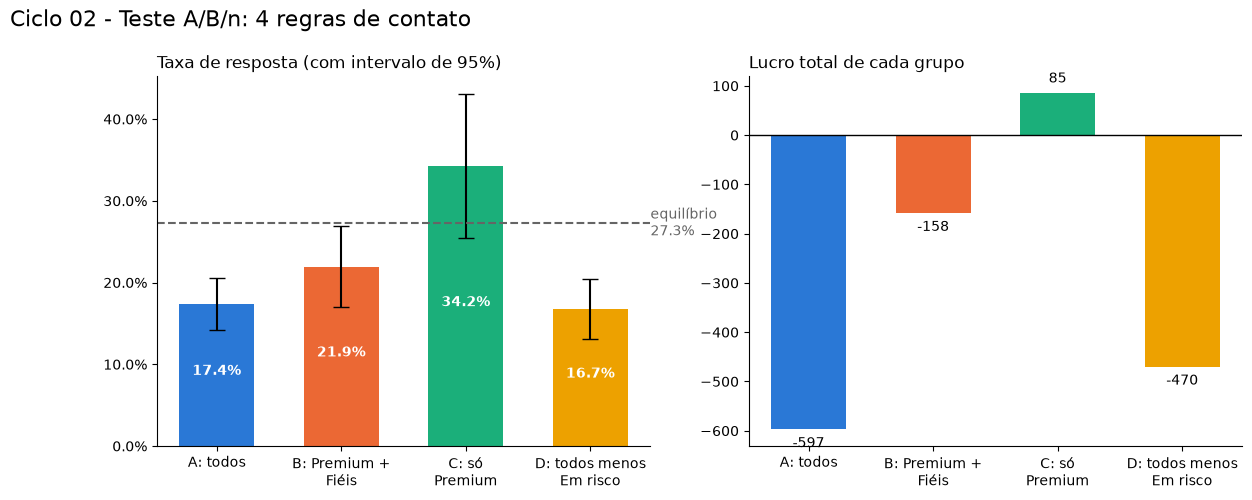

In [22]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8))
plt.suptitle('Ciclo 02 - Teste A/B/n: 4 regras de contato', fontsize=16, x=0.02, ha='left', y=1.02)
nomes = ['A: todos', 'B: Premium +\nFiéis', 'C: só\nPremium', 'D: todos menos\nEm risco']

erro = 1.96 * np.sqrt(resumo2['taxa'] * (1 - resumo2['taxa']) / resumo2['contatos'])
eixos[0].bar(nomes, resumo2['taxa'], yerr=erro, color=CORES[:4], width=0.6, capsize=6)
eixos[0].axhline(PONTO_EQUILIBRIO, color='#656565', ls='--', lw=1.5)
eixos[0].text(3.45, PONTO_EQUILIBRIO, f' equilíbrio\n {PONTO_EQUILIBRIO:.1%}', va='center', color='#656565')
for i, taxa in enumerate(resumo2['taxa']):
    eixos[0].text(i, taxa / 2, f'{taxa:.1%}', ha='center', color='white', fontweight='bold')
eixos[0].set_title('Taxa de resposta (com intervalo de 95%)', loc='left')
eixos[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))

eixos[1].bar(nomes, resumo2['lucro_total'], color=CORES[:4], width=0.6)
eixos[1].axhline(0, color='black', lw=1)
for i, valor in enumerate(resumo2['lucro_total']):
    eixos[1].text(i, valor + (15 if valor >= 0 else -15), f'{valor:,}', ha='center',
                  va='bottom' if valor >= 0 else 'top')
eixos[1].set_title('Lucro total de cada grupo', loc='left')

for eixo in eixos:
    eixo.spines[['top', 'right']].set_visible(False)
salvar('Teste AB - Ciclo 02')
plt.show()

## Passo 5 - Conclusões

📌 **Nota**
- ✅ **Para o negócio:** a regra vencedora é **C: só Premium**. É a única com taxa acima do ponto de equilíbrio (**34,2%**) e com lucro positivo (**+85**, ou **+0,15** por cliente do grupo).
- 🔎 As duas métricas concordam: na taxa, o qui-quadrado e o post-hoc apontam a regra C; no lucro, o Kruskal-Wallis confirma a diferença entre as regras.
- 💡 **Lição do Ciclo 02:** testar várias versões de uma vez exige **duas etapas**: o teste geral ("existe diferença?") e o post-hoc com correção ("onde está?").
- ⚠️ A regra C teve só 111 contatos, então o intervalo da taxa dela é largo (veja a barra de erro). O Ciclo 03 mostra outra forma de medir essa incerteza.

# Ciclo 03 - Teste A-B Bayesiano

> **Pergunta:** *dá para decidir o Ciclo 01 mais cedo, acompanhando o teste dia a dia?*

No mundo real, os resultados chegam **aos poucos** e o diretor quer saber todo dia "e aí, qual está ganhando?". Este ciclo refaz o Ciclo 01 (A: todos × B: Premium + Fiéis) com os clientes chegando ao longo de **20 dias**.

## Passo 1 - Escolha do método: Frequentista × Bayesiano

| | **Frequentista** (Ciclos 01 e 02) | **Bayesiano** (este ciclo) |
|---|---|---|
| Pergunta que responde | "Se não houvesse diferença, qual a chance de ver um resultado assim?" (p-valor) | "Qual a probabilidade de B ser melhor que A?" |
| Quando decide | Só no fim, com o tamanho de amostra planejado | A qualquer momento, com a regra de parada definida antes |
| Como falar com o negócio | "Rejeitamos H0 com 5% de significância" | "A chance de B ser melhor é alta e o risco de errar é pequeno" |

### Como o Bayesiano funciona
Para cada grupo, a taxa de resposta é descrita por uma **distribuição Beta**, a distribuição natural para "sucesso ou fracasso":

```
   Beta( 1 + respostas , 1 + não respostas )

   no começo (sem dados):  ▁▁▁▁▁▁▁▁▁▁   qualquer taxa é possível
   com poucos dados:         ▂▅█▅▂      a taxa provável aparece
   com muitos dados:          ▁█▁       a taxa fica bem definida
```

Sorteando milhares de taxas possíveis de A e de B, calculamos:
- **P(B > A):** em quantos sorteios B ganhou de A.
- **Perda esperada:** se escolhermos B e na verdade A for melhor, **quanto de taxa perdemos em média**. É o "risco" da decisão.
- **P(dar lucro):** em quantos sorteios a taxa passou do ponto de equilíbrio (27,3%).

Essa técnica de "sortear milhares de valores e contar" é a **aproximação de Monte Carlo** (Aula 31). No curso, as taxas são sorteadas de uma Normal e corrigidas por pesos (amostragem por importância). Aqui sorteamos **direto da Beta** com o `numpy`. É o mesmo cálculo, só que mais simples e sem aproximação.

> 📚 **No curso:** Aula 27 (o problema: decidir em menos de 7 dias), Aula 30 (p-valor dia a dia com os dados acumulados), Aula 31 (estatística Bayesiana e Monte Carlo), Aula 32 (P(B > A) e risco esperado), Aula 33 (planejamento, com o passo **2.3. Escolha da perda máxima aceitável**), Aula 35 (a decisão: perda esperada ≤ perda máxima), notebook **Teste Frequentista VS Bayesiana**.

## Passo 2 - Design do experimento: a regra de parada (definida ANTES de olhar os dados)
- **Frequentista:** decide quando o p-valor cai abaixo de 5%.
- **Bayesiano (como na Aula 35):** escolhe B quando a **perda esperada de escolher B** for **menor ou igual à perda máxima aceitável**. P(B > A) é reportada junto, para o negócio.
- **Perda máxima aceitável = 0,5 ponto percentual de taxa.** Em dinheiro, errar por 0,5 ponto custa 0,005 × 11 = **0,055 por contato**, um risco pequeno perto do custo de 3 de cada contato.

💡 No curso, a perda máxima foi de **0,0001** (0,01 ponto), escolhida para um site com cerca de 24 mil visitas por dia em cada página. Com só cerca de 80 contatos por dia, um limite tão rígido não seria atingido em 20 dias (conferido abaixo): **a perda máxima depende do tamanho do negócio e do custo do erro**.

## Passo 3 - Coleta e preparação dos dados: os clientes chegam dia a dia

In [23]:
dias = 20
ciclo3 = ciclo1.sample(frac=1, random_state=42).reset_index(drop=True)   # ordem de chegada sorteada
ciclo3['dia'] = np.arange(len(ciclo3)) * dias // len(ciclo3) + 1

contatados3 = ciclo3[ciclo3['contatado'] == 1]
diario = (contatados3.pivot_table(index='dia', columns='grupo', values='Response', aggfunc=['sum', 'count'])
                     .cumsum())   # valores ACUMULADOS até cada dia
diario.columns = ['respostas_A', 'respostas_B', 'contatos_A', 'contatos_B']
diario.head()

,respostas_A,respostas_B,contatos_A,contatos_B
dia,,,,
1,13,9,55,29
2,27,16,103,52
3,35,23,159,77
4,42,25,219,95
5,52,32,282,123


## Passo 4 - Teste das hipóteses, todo dia

In [24]:
linhas = []
for dia, d in diario.iterrows():
    sucessos = [d['respostas_A'], d['respostas_B']]
    contatos = [d['contatos_A'], d['contatos_B']]
    freq = teste_z_proporcoes(sucessos, contatos)
    bayes = comparar_bayesiano(sucessos, contatos, semente=dia)
    linhas.append({'dia': dia, 'contatos': int(sum(contatos)), 'taxa A': freq['taxa A'], 'taxa B': freq['taxa B'],
                   'p-valor': freq['p-valor'], **bayes})
acompanhamento = pd.DataFrame(linhas).set_index('dia')
acompanhamento

,contatos,taxa A,taxa B,p-valor,P(B > A),perda ao escolher A,perda ao escolher B,P(A dá lucro),P(B dá lucro)
dia,,,,,,,,,
1,84,0.2364,0.3103,0.4634,0.7762,0.0894,0.0123,0.3043,0.7134
2,155,0.2621,0.3077,0.5498,0.7327,0.0599,0.0120,0.4322,0.7396
3,236,0.2201,0.2987,0.1887,0.9068,0.0826,0.0025,0.0724,0.7192
4,314,0.1918,0.2632,0.1561,0.9251,0.0752,0.0016,0.0030,0.4463
5,405,0.1844,0.2602,0.0837,0.9581,0.0780,0.0007,0.0003,0.4013
6,486,0.1869,0.2282,0.2942,0.8576,0.0457,0.0028,0.0001,0.1189
7,566,0.1735,0.2184,0.2062,0.8994,0.0481,0.0017,0.0000,0.0560
8,646,0.1689,0.2178,0.1372,0.9321,0.0510,0.0010,0.0000,0.0398
9,729,0.1619,0.2043,0.1605,0.9227,0.0446,0.0010,0.0000,0.0086


In [25]:
perda_maxima = 0.005   # 0,5 ponto percentual de taxa
dia_freq = acompanhamento.index[acompanhamento['p-valor'] < alpha]
dia_bayes = acompanhamento.index[acompanhamento['perda ao escolher B'] <= perda_maxima]
dia_curso = acompanhamento.index[acompanhamento['perda ao escolher B'] <= 0.0001]
print('Frequentista decide no dia:', dia_freq.min() if len(dia_freq) else 'não decide em 20 dias')
print('Bayesiano decide no dia:   ', dia_bayes.min() if len(dia_bayes) else 'não decide em 20 dias')
print('Bayesiano com a perda máxima do curso (0,0001):', dia_curso.min() if len(dia_curso) else 'não decide em 20 dias')

Frequentista decide no dia: 14
Bayesiano decide no dia:    3
Bayesiano com a perda máxima do curso (0,0001): não decide em 20 dias


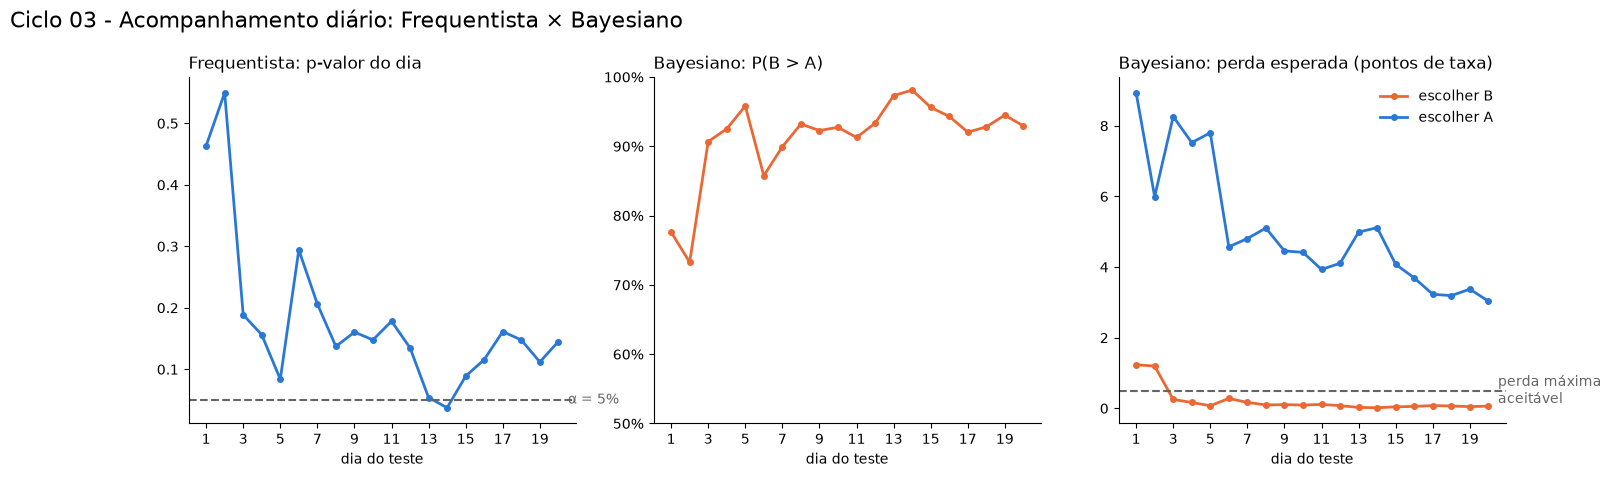

In [26]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.5))
plt.suptitle('Ciclo 03 - Acompanhamento diário: Frequentista × Bayesiano', fontsize=16, x=0.02, ha='left', y=1.03)

eixos[0].plot(acompanhamento.index, acompanhamento['p-valor'], color=CORES[0], lw=2, marker='o', ms=4)
eixos[0].axhline(alpha, color='#656565', ls='--', lw=1.5)
eixos[0].text(20.3, alpha, ' α = 5%', va='center', color='#656565')
eixos[0].set_title('Frequentista: p-valor do dia', loc='left')

eixos[1].plot(acompanhamento.index, acompanhamento['P(B > A)'], color=CORES[1], lw=2, marker='o', ms=4)
eixos[1].set_title('Bayesiano: P(B > A)', loc='left')
eixos[1].set_ylim(0.5, 1)
eixos[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))

eixos[2].plot(acompanhamento.index, acompanhamento['perda ao escolher B'] * 100, color=CORES[1], lw=2,
              marker='o', ms=4, label='escolher B')
eixos[2].plot(acompanhamento.index, acompanhamento['perda ao escolher A'] * 100, color=CORES[0], lw=2,
              marker='o', ms=4, label='escolher A')
eixos[2].axhline(0.5, color='#656565', ls='--', lw=1.5)
eixos[2].text(20.3, 0.5, ' perda máxima\n aceitável', va='center', color='#656565')
eixos[2].set_title('Bayesiano: perda esperada (pontos de taxa)', loc='left')
eixos[2].legend(frameon=False)

for eixo in eixos:
    eixo.set_xlabel('dia do teste')
    eixo.set_xticks(range(1, dias + 1, 2))
    eixo.spines[['top', 'right']].set_visible(False)
salvar('Teste AB - Ciclo 03')
plt.show()

📌 **Nota**
- 🔎 **Frequentista:** o p-valor sobe e desce. No **dia 14** ele fica abaixo de 5% (**0,037**) e depois volta a subir, até **0,145** no dia 20. Se tivéssemos parado no dia 14, teríamos declarado um vencedor que **some** com mais dados. É o problema de **"espiar"** o teste: o p-valor só vale no tamanho de amostra planejado, e olhar todo dia aumenta muito a chance de um falso alarme.
- 🔎 **Bayesiano:** no **dia 3**, a perda esperada de escolher B já é de **0,25 ponto** (abaixo da perda máxima aceitável de 0,5), com P(B > A) de **90,7%**, e a regra de parada escolhe B. Com a perda máxima do curso (**0,0001**), **não haveria decisão em 20 dias**: a perda de B nunca fica abaixo de **0,0002**. Depois disso, a perda de B nunca passa de **0,28 ponto**. Ou seja, a decisão do dia 3 se manteve até o dia 20, quando P(B > A) termina em **92,9%**.
- ⚠️ O Bayesiano também precisa de disciplina. P(B > A) sobe e desce (chegou a **95,8%** no dia 5 e caiu para **85,8%** no dia 6), por isso a decisão se apoia na **perda esperada**, como ensina a Aula 35, e não só na probabilidade. E decidir no dia 3, com só **77 contatos** no B, é arriscado. Na prática, a regra de parada vem junto com uma **duração mínima** (por exemplo, uma semana inteira, para cobrir todos os dias da semana).

### 4.1. A pergunta que o negócio quer ouvir: "isso dá lucro?"
O Bayesiano responde direto à chance de cada regra passar do ponto de equilíbrio. Fazemos a conta para o Ciclo 01 e para a regra vencedora do Ciclo 02 (C: só Premium contra A: todos).

In [27]:
fim = acompanhamento.iloc[-1]
print(f"Ciclo 01 no dia 20 - P(A dá lucro): {fim['P(A dá lucro)']:.1%} | P(B dá lucro): {fim['P(B dá lucro)']:.1%}")

a2, c2 = resumo2.loc['A: todos'], resumo2.loc['C: só Premium']
bayes_c = comparar_bayesiano([a2['respostas'], c2['respostas']], [a2['contatos'], c2['contatos']])
print(f"Ciclo 02 - P(C > A): {bayes_c['P(B > A)']:.1%} | P(C dá lucro): {bayes_c['P(B dá lucro)']:.1%}")

Ciclo 01 no dia 20 - P(A dá lucro): 0.0% | P(B dá lucro): 0.0%
Ciclo 02 - P(C > A): 100.0% | P(C dá lucro): 95.1%


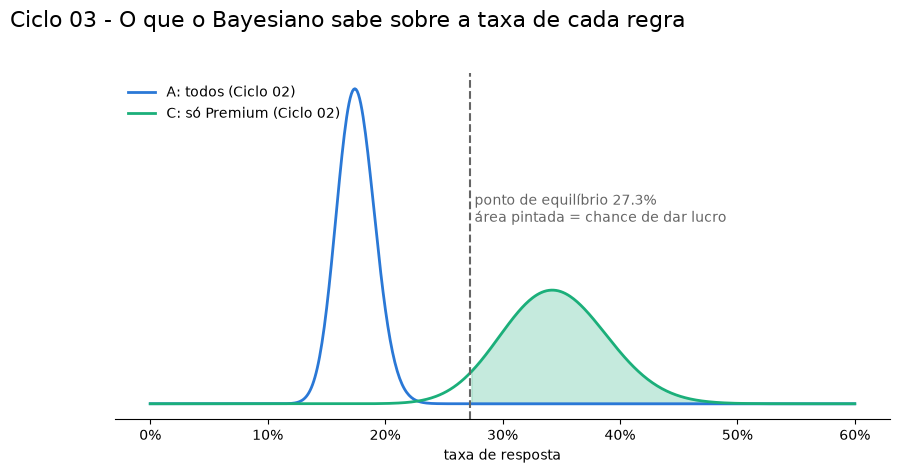

In [28]:
fig, eixo = plt.subplots(figsize=(10, 4.5))
plt.suptitle('Ciclo 03 - O que o Bayesiano sabe sobre a taxa de cada regra', fontsize=16, x=0.02, ha='left', y=1.02)
x = np.linspace(0, 0.6, 600)
for nome, s, n, cor in [('A: todos (Ciclo 02)', a2['respostas'], a2['contatos'], CORES[0]),
                        ('C: só Premium (Ciclo 02)', c2['respostas'], c2['contatos'], CORES[2])]:
    eixo.plot(x, stats.beta.pdf(x, 1 + s, 1 + n - s), color=cor, lw=2, label=nome)
    eixo.fill_between(x, stats.beta.pdf(x, 1 + s, 1 + n - s), where=x > PONTO_EQUILIBRIO, color=cor, alpha=0.25)
eixo.axvline(PONTO_EQUILIBRIO, color='#656565', ls='--', lw=1.5)
eixo.text(PONTO_EQUILIBRIO, eixo.get_ylim()[1] * 0.55, f' ponto de equilíbrio {PONTO_EQUILIBRIO:.1%}\n área pintada = chance de dar lucro',
          color='#656565')
eixo.set_xlabel('taxa de resposta')
eixo.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
eixo.set_yticks([])
eixo.legend(frameon=False, loc='upper left')
eixo.spines[['top', 'right', 'left']].set_visible(False)
salvar('Teste AB - Ciclo 03 - distribuicoes Beta')
plt.show()

📌 **Nota**
- 🔎 No dia 20 do Ciclo 01, a chance de dar lucro é de **0,0%** para A e **0,0%** para B: com os dados que temos, nenhuma das duas regras se paga.
- 🔎 Para a regra C do Ciclo 02: P(C > A) = **100,0%** e P(C dá lucro) = **95,1%**.
- 💡 No gráfico, a curva de A é estreita (muitos contatos) e fica toda à esquerda do equilíbrio. A curva de C é larga (só 111 contatos), mas quase toda à direita. A área pintada é a chance de dar lucro.

## Passo 5 - Conclusões

📌 **Nota**
- ✅ **Para o negócio:** o Bayesiano fala a língua do diretor: "a regra só Premium tem **95,1%** de chance de dar lucro" é mais fácil de usar do que "rejeitamos H0 com p < 0,05".
- 💡 **Lição do Ciclo 03:** o frequentista pede um tamanho de amostra fixo e só vale no fim. O Bayesiano pode ser acompanhado todo dia, desde que a regra de parada (probabilidade, perda máxima e duração mínima) seja definida **antes**.
- ⚠️ Os dois têm o mesmo problema: durante o teste, metade dos contatos vai para a regra pior. O Ciclo 04 ataca esse custo.

# Ciclo 04 - MAB (Multi-Armed Bandit)

> **Pergunta:** *dá para aprender qual segmento responde mais SEM desperdiçar tantos contatos durante o teste?*

Em todo Teste A/B, enquanto o teste roda, **metade (ou mais) dos contatos vai para as versões piores**. No Ciclo 02, três de quatro grupos deram prejuízo durante o teste inteiro. O **Multi-Armed Bandit** resolve isso: ele vai **mudando a divisão durante o teste**, mandando mais contatos para quem está respondendo melhor.

## Passo 1 - Escolha do método

O nome vem das máquinas caça-níquel ("bandidos de um braço só"). Imagine 4 máquinas, uma por segmento, cada uma com uma chance desconhecida de pagar:

```
   🎰 Premium   🎰 Fiéis   🎰 Novos   🎰 Em risco      ◄─ cada braço é um segmento
      ?%           ?%         ?%          ?%            ◄─ taxa de resposta desconhecida

   a cada contato, o agente escolhe um braço ──► o cliente responde (1) ou não (0)
                     ▲                                          │
                     └────────── aprende com a resposta ◄───────┘
```

O dilema é **explorar × aproveitar** (*exploration × exploitation*):
- **Explorar:** testar segmentos para descobrir qual é o melhor.
- **Aproveitar:** usar o que já sabemos e contatar o melhor segmento.

### Os 5 agentes do curso
| Agente | Como escolhe o segmento | Na prática |
|---|---|---|
| **Aleatório** | Sempre ao acaso, em partes iguais | É o que um **Teste A/B/n** faz durante todo o teste |
| **Onisciente** | Já sabe qual é o melhor | Não existe: serve de referência do máximo possível |
| **Guloso** | Testa cada um 1 vez e fica com o melhor | Decide cedo demais e pode ficar preso no errado |
| **ε-Guloso (ε decrescente)** | Explora ao acaso com probabilidade ε, e o ε cai a cada contato: ε = (1 − 1%)^contato | Explora muito no começo e quase nada no fim; a dificuldade é escolher o decaimento |
| **Thompson** | Sorteia uma taxa de cada Beta e contata o maior sorteio | Explora quando há dúvida e aproveita quando há certeza, sozinho |

Com decaimento de 1%, o ε começa em 100%, cai para **37%** depois de 100 contatos e para menos de **5%** depois de 300 (é a tabela "Epsilon Decreasing" da Aula 41).

> 📚 **No curso:** Aula 36 (o problema do MAB e as políticas: Random, Omniscient, ε-Greedy, UCB e Thompson), Aulas 37 e 38 (agentes Aleatório e Onisciente), Aula 39 (dilema explorar × aproveitar e a perda de vendas do teste A/B tradicional), Aula 40 (Guloso), Aula 41 (ε-Guloso com ε decrescente), Aula 42 (Thompson com a Beta), Aula 43 (comparação dos agentes), notebook **MAB (Multi-Armed Bandit)**. Usamos os mesmos parâmetros do curso: **1.000 contatos** (*trials*) e **200 episódios**. O **UCB**, citado na Aula 36, não foi implementado no curso e ficou de fora.

## Passo 2 - Design do experimento
- **Braços:** os 4 segmentos.
- **Orçamento:** **1.000 contatos** por campanha (menos da metade da base).
- **Recompensa:** a resposta **real** de um cliente sorteado do segmento escolhido (1 = aceitou, 0 = não aceitou).
- **Repetições:** cada agente roda **200 campanhas** para medirmos o comportamento médio, e não a sorte de uma única rodada.
- **Métricas:** respostas, lucro, **arrependimento** (*regret*: quantas respostas a menos que o Onisciente) e % dos contatos no Premium.

## Passo 3 e 4 - Simulação dos agentes

In [29]:
respostas_por_segmento = [df.loc[df['segmento'] == s, 'Response'].to_numpy() for s in ORDEM]
taxas_reais = [r.mean() for r in respostas_por_segmento]

orcamento, campanhas = 1_000, 200
agentes = [AgenteAleatorio,
           lambda k, rng: AgenteOnisciente(k, rng, taxas_reais),
           AgenteGuloso,
           lambda k, rng: AgenteEpsilonGuloso(k, rng, decaimento=0.01),
           AgenteThompson]

resultados = [simular_bandit(criar, respostas_por_segmento, orcamento, campanhas, semente=42) for criar in agentes]

melhor = resultados[1]['respostas acumuladas'][-1]
tabela_mab = pd.DataFrame([{
    'agente': r['agente'],
    'respostas': r['respostas acumuladas'][-1],
    'taxa de resposta': r['respostas acumuladas'][-1] / orcamento,
    'lucro': RECEITA_RESPOSTA * r['respostas acumuladas'][-1] - CUSTO_CONTATO * orcamento,
    'arrependimento (respostas)': melhor - r['respostas acumuladas'][-1],
    **{f'% contatos {s}': f for s, f in zip(ORDEM, r['fração por braço'])}} for r in resultados]).set_index('agente')
tabela_mab

,respostas,taxa de resposta,lucro,arrependimento (respostas),% contatos Premium,% contatos Fiéis de alto volume,% contatos Novos e ativos,% contatos Em risco de churn
agente,,,,,,,,
Aleatório (A/B/n),163.6150,0.1636,"-1,200.2350",170.6750,0.2503,0.2500,0.2509,0.2489
Onisciente,334.2900,0.3343,677.1900,0.0000,1.0000,0.0000,0.0000,0.0000
Guloso,299.0300,0.2990,289.3300,35.2600,0.8221,0.0461,0.1156,0.0162
ε-Guloso (decaimento 1%),310.6100,0.3106,416.7100,23.6800,0.8954,0.0281,0.0517,0.0248
Thompson,316.4050,0.3164,480.4550,17.8850,0.9093,0.0315,0.0409,0.0184


📌 **Nota**
- 🔎 **Aleatório (= A/B/n):** **164** respostas em 1.000 contatos (**16,4%**) e lucro de **−1.200**. É o custo de dividir os contatos em partes iguais durante o teste inteiro.
- 🔎 **Thompson:** **316** respostas (**31,6%**) e lucro de **+480**, com **91%** dos contatos no Premium. Ficou só **17,9 respostas** atrás do Onisciente (**334**), contra **170,7** do Aleatório.
- 🔎 **Guloso:** **299** respostas e **82%** no Premium. Em parte das campanhas ele "trava" no segmento errado: mandou **11,6%** dos contatos para Novos e ativos.
- 🔎 **ε-Guloso com ε decrescente:** **311** respostas e **90%** no Premium. Explorar no começo resolve o problema do Guloso, mas o resultado depende do decaimento escolhido (1% aqui). É a "maior dificuldade" que a Aula 41 aponta.
- 🔎 Os resultados repetem o padrão da Aula 43 do curso: o Aleatório fica perto da metade do máximo, e o Guloso, o ε-Guloso e o Thompson ficam perto do Onisciente.
- ⚠️ A base tem só **417** clientes Premium. O Ciclo 04 imagina um **fluxo contínuo** de clientes novos com o perfil de cada segmento (como visitantes chegando a um site), por isso o cliente é sorteado **com reposição**.

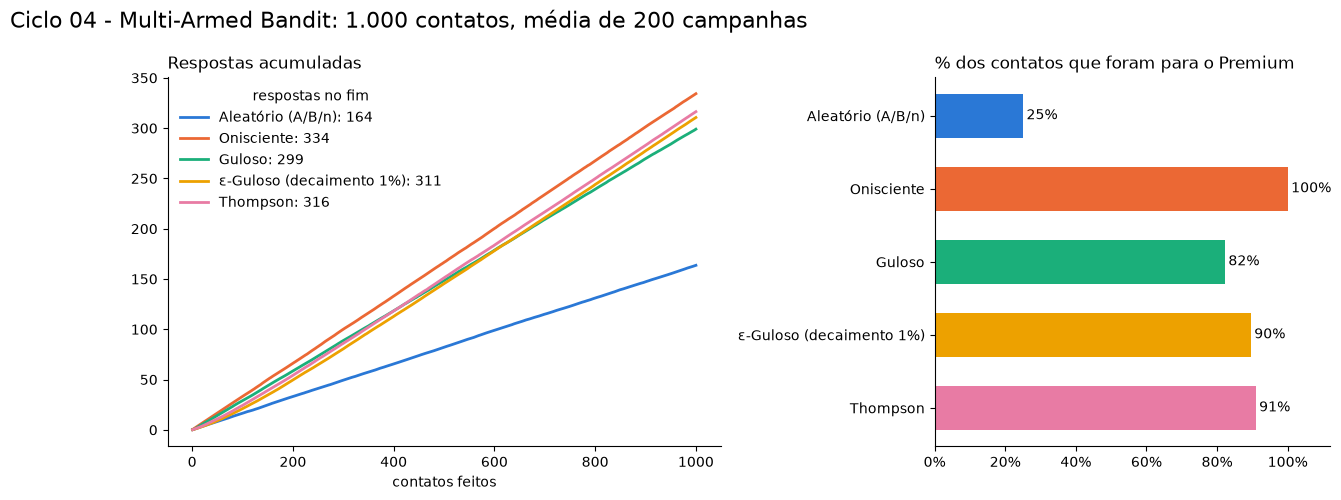

In [30]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.4, 1], 'wspace': 0.45})
plt.suptitle('Ciclo 04 - Multi-Armed Bandit: 1.000 contatos, média de 200 campanhas', fontsize=16,
             x=0.02, ha='left', y=1.02)

contatos = np.arange(1, orcamento + 1)
for r, cor in zip(resultados, CORES):
    curva = r['respostas acumuladas']
    eixos[0].plot(contatos, curva, color=cor, lw=2, label=f"{r['agente']}: {curva[-1]:.0f}")
eixos[0].set_xlabel('contatos feitos')
eixos[0].set_title('Respostas acumuladas', loc='left')
eixos[0].legend(frameon=False, loc='upper left', title='respostas no fim')

premium = [r['fração por braço'][0] for r in resultados]
nomes_agentes = [r['agente'] for r in resultados]
eixos[1].barh(nomes_agentes, premium, color=CORES[:5], height=0.6)
for i, valor in enumerate(premium):
    eixos[1].text(valor + 0.01, i, f'{valor:.0%}', va='center')
eixos[1].invert_yaxis()
eixos[1].set_xlim(0, 1.12)
eixos[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
eixos[1].set_title('% dos contatos que foram para o Premium', loc='left')

for eixo in eixos:
    eixo.spines[['top', 'right']].set_visible(False)
salvar('Teste AB - Ciclo 04')
plt.show()

📌 **Nota**
- 🔎 As curvas do Thompson, do ε-Guloso e do Guloso quase colam na do Onisciente, enquanto a do Aleatório cresce na metade do ritmo.
- 💡 A diferença entre o Aleatório (**−1.200**) e o Thompson (**+480**) numa única campanha de 1.000 contatos é o **preço de aprender** de um A/B/n: ele descobre o melhor segmento, mas paga por isso mandando 3 de cada 4 contatos para segmentos que dão prejuízo.

### Como o Thompson aprende (uma campanha, passo a passo)
Cada curva é a Beta de um segmento: **larga** quando o agente ainda tem dúvida, **estreita** quando já sabe. Repare como o Premium (azul) vai se separando dos demais e recebendo quase todos os contatos.

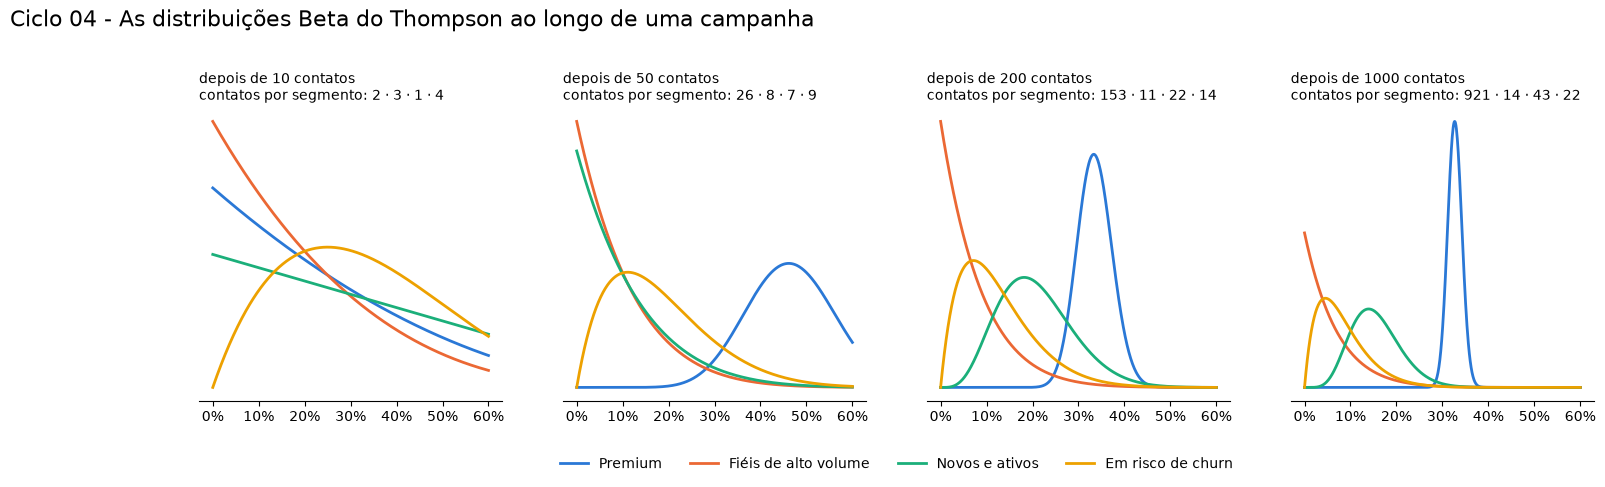

In [31]:
rng = np.random.default_rng(42)
agente = AgenteThompson(len(ORDEM), rng)
momentos, fotos = [10, 50, 200, 1000], {}
for t in range(1, orcamento + 1):
    braco = agente.escolher()
    agente.atualizar(braco, rng.choice(respostas_por_segmento[braco]))
    if t in momentos:
        fotos[t] = (agente.respostas.copy(), agente.contatos.copy())

fig, eixos = plt.subplots(1, 4, figsize=(18, 3.8), sharey=False)
plt.suptitle('Ciclo 04 - As distribuições Beta do Thompson ao longo de uma campanha', fontsize=16,
             x=0.02, ha='left', y=1.14)
x = np.linspace(0, 0.6, 600)
for eixo, t in zip(eixos, momentos):
    respostas, contatos_seg = fotos[t]
    for i, (segmento, cor) in enumerate(zip(ORDEM, CORES)):
        eixo.plot(x, stats.beta.pdf(x, 1 + respostas[i], 1 + contatos_seg[i] - respostas[i]), color=cor, lw=2,
                  label=segmento)
    divisao = ' · '.join(f'{c:.0f}' for c in contatos_seg)
    eixo.set_title(f'depois de {t} contatos\ncontatos por segmento: {divisao}', loc='left', fontsize=10)
    eixo.set_yticks([])
    eixo.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    eixo.spines[['top', 'right', 'left']].set_visible(False)
eixos[0].legend(frameon=False, loc='upper center', bbox_to_anchor=(2.3, -0.15), ncol=4)
salvar('Teste AB - Ciclo 04 - Thompson')
plt.show()

📌 **Nota**
- 🔎 **Depois de 10 contatos**, as 4 curvas são largas e se cruzam: o agente ainda não sabe nada e explora todos (**2 · 3 · 1 · 4** contatos).
- 🔎 **Depois de 50**, a curva do Premium já se separa das outras e recebe **26** dos 50 contatos.
- 🔎 **Depois de 200**, o Premium recebeu **153**. **Depois de 1.000**, recebeu **921**, e a curva dele fica bem estreita, em torno de 33%.
- 💡 O Thompson **nunca para de explorar** de vez (ainda manda **14 · 43 · 22** contatos aos outros segmentos). Se o comportamento dos clientes mudar, ele percebe sozinho.

## Passo 5 - Conclusões

📌 **Nota**
- ✅ **Para o negócio:** o Thompson descobriu sozinho que o Premium é o melhor segmento e terminou a campanha **no lucro** (+480), enquanto a divisão em partes iguais terminou no prejuízo (−1.200).
- 💡 **Lição do Ciclo 04:** o MAB troca **medir com precisão** por **ganhar durante o teste**. Os segmentos piores recebem tão poucos contatos (14 nos Fiéis) que não dá para calcular um intervalo de confiança bom para eles. Ele responde "onde investir agora", e não "quanto exatamente cada segmento converte".

# ✅ Conclusão: o teste ideal e a aplicação em produção

## Os 4 testes lado a lado

| | **Ciclo 01: A/B** | **Ciclo 02: A/B/n** | **Ciclo 03: Bayesiano** | **Ciclo 04: MAB (Thompson)** |
|---|---|---|---|---|
| **Pergunta** | B é melhor que A? | Qual de várias regras é a melhor? | Qual a chance de B ser melhor / dar lucro? | Para onde mandar o próximo contato? |
| **Resultado aqui** | B perde menos (lucro −0,43 × −1,20 por cliente), mas ainda perde | Só Premium: 34,2% de resposta e +85 de lucro | Só Premium: 95,1% de chance de dar lucro | 316 respostas e +480 de lucro, a 17,9 respostas do máximo |
| **Ponto forte** | Simples, padrão de mercado | Compara várias versões sem falsos alarmes | Pode ser acompanhado todo dia; fala a língua do negócio | Ganha enquanto aprende |
| **Ponto fraco** | Tamanho de amostra fixo; uma pergunta por vez | Divide os contatos em partes iguais: caro durante o teste | Regra de parada e duração mínima precisam ser definidas antes | Mede mal os braços piores; não dá um p-valor "limpo" |
| **Use quando** | Decisão única entre duas versões | Decisão única entre várias versões | Precisa decidir rápido ou reportar risco | A campanha é contínua e o objetivo é o retorno |

## 🏆 O teste ideal para este projeto

A campanha deste projeto **se repete** (houve 6 campanhas na base) e a decisão é sempre a mesma: **para quem mandar**. Por isso, o teste ideal combina dois ciclos:

1. **Validar uma vez com um A/B/n** (Ciclo 02), lido também pelo lado Bayesiano (Ciclo 03). Ele dá a prova que o diretor pede antes de mudar a regra: "só Premium" foi a única regra que passou do ponto de equilíbrio (**34,2%**), com **95,1%** de chance de dar lucro.
2. **Rodar no dia a dia com o MAB de Thompson** (Ciclo 04). Ele mantém a campanha no lucro enquanto continua aprendendo: **+480** contra **−1.200** de uma divisão em partes iguais, a só **17,9** respostas do máximo possível.

> 🏆 **Teste ideal: Multi-Armed Bandit com Thompson Sampling em produção, depois de uma validação inicial com A/B/n**, com um pequeno grupo de controle fixo para continuar medindo o ganho real.

## 🚀 Como aplicar em produção

```
                  ┌────────────────────────────────────────────────────┐
  novos clientes ─►  1. SEGMENTAR com o pipeline salvo (Model/)        │
  e respostas     │     só com o histórico de antes da campanha        │
  do CRM          └──────────────────────┬─────────────────────────────┘
                                         ▼
                  ┌────────────────────────────────────────────────────┐
                  │  2. SORTEIO:  10% controle   │   90% Thompson      │
                  │     (divisão fixa, mede o    │   (manda o contato  │
                  │      ganho real)             │    para o segmento  │
                  │                              │    com maior Beta)  │
                  └──────────────────────┬─────────────────────────────┘
                                         ▼
                  ┌────────────────────────────────────────────────────┐
                  │  3. CONTATAR e esperar a resposta                  │
                  └──────────────────────┬─────────────────────────────┘
                                         ▼
                  ┌────────────────────────────────────────────────────┐
                  │  4. ATUALIZAR as Betas (respostas e contatos por   │
                  │     segmento) todo dia, numa tabela                │
                  └──────────────────────┬─────────────────────────────┘
                                         ▼
                  ┌────────────────────────────────────────────────────┐
                  │  5. RELATÓRIO semanal: P(dá lucro) e perda         │
                  │     esperada por segmento; ganho contra o controle │
                  └────────────────────────────────────────────────────┘
```

| Peça | Como fazer |
|---|---|
| **Grupo de controle fixo (~10%)** | Recebe a campanha por divisão igual entre os segmentos. Sem ele, não dá para provar quanto o bandit está ganhando. |
| **Estado do bandit** | Uma tabela com respostas e contatos por segmento. A função `AgenteThompson.escolher` de `src/teste_ab.py` decide o próximo segmento. Pode virar uma API, como nas Aulas 44 e 45 do curso (Teste A/B Bayesiano + MAB num app Flask, com um endpoint que recebe as respostas e atualiza os dados), ou um job diário. |
| **Limites de segurança** | Um mínimo de contatos para cada segmento (por exemplo, 5%), para que ele continue aprendendo; alerta se P(Premium dá lucro) cair abaixo de 50%; teto de contatos por cliente. |
| **Quando refazer o teste** | Ao mudar a oferta, o preço ou o custo do contato (que muda o ponto de equilíbrio de 27,3%), ou quando o relatório mostrar que um segmento mudou de comportamento: aí roda-se um novo A/B/n. |
| **Sem vazamento** | O segmento de cada cliente é sempre calculado só com o que se sabia **antes** da campanha. |

## ⚠️ Limites deste estudo

- 🔁 **Replay:** os experimentos foram reconstruídos com as respostas reais de **uma** campanha, que foi enviada a todos. Supõe-se que a oferta é a mesma e que um cliente não influencia o outro. Um teste de verdade contataria os grupos em paralelo, no mesmo período.
- 📉 **Amostras pequenas:** no Ciclo 01, o grupo B teve **530** contatos para os **903** planejados; no Ciclo 02, a regra C teve **111** para os **134** planejados. Os resultados mudam um pouco com outro sorteio (por isso as sementes são fixas).
- 👥 **Base limitada:** só há **417** clientes Premium. O Ciclo 04 imagina um fluxo contínuo de clientes novos e sorteia com reposição.
- 💰 **Lucro simplificado:** usamos o custo (3) e a receita (11) fixos da base. Não entram o valor do cliente no longo prazo nem o incômodo de quem recebe ofertas demais.
- 🎯 **Resposta não é ganho incremental:** medimos quem **aceitou** a oferta. Parte dessas pessoas talvez comprasse de qualquer jeito. Medir o ganho incremental exigiria um grupo do mesmo segmento que **não** recebe a campanha.

## 📚 Validação com o material do curso

Cada método deste notebook foi conferido com as anotações e os PDFs das aulas do curso (pasta `1.10 - Teste A-B`):

| Ciclo | O que o curso ensina | O que o notebook fez | Situação |
|---|---|---|---|
| Todos | Os 5 passos: método → design → dados → teste → conclusão (Aulas 2, 15, 19, 33) | Mesma estrutura em todos os ciclos | ✅ igual ao curso |
| 01 | Hipóteses bicaudais, α = 5%, poder = 80%, Cohen's h e `NormalIndPower` (Aulas 5 e 6) | Igual; o cálculo reproduz os 4.720 do PA James quando usamos 13% → 15% | ✅ igual ao curso |
| 01 | Efeito mínimo pela meta do negócio ou pelo custo (Aula 8) | Meta de +5 pontos; o custo aparece no ponto de equilíbrio de 27,3% | ✅ igual ao curso |
| 01 | Checar duplicados e homogeneidade dos grupos (Aula 7, PA Bond) | Igual, mais a checagem do sorteio (SRM) | ✅ com um passo a mais |
| 01 | Mapa da Aula 9: proporção com 2 grupos → Z ou qui-quadrado | Teste Z e qui-quadrado, com o mesmo p-valor (0,1452) | ✅ igual ao curso |
| 01 | Média sem suposições paramétricas, 2 grupos → Mann-Whitney ou Welch (Aulas 10 e 11) | Welch e Mann-Whitney no lucro | ✅ igual ao curso |
| 02 | Qui-quadrado geral + post-hoc com Bonferroni; erro α acumulado (Aulas 15, 17, 21) | Igual | ✅ igual ao curso |
| 02 | Tamanho da amostra pelo w de Cohen (Aula 19) | Igual, mas com `GofChisquarePower` em vez do `TTestIndPower` do notebook PA James ABN | ⚠️ diferente, conferido por simulação: 79,6% de poder com 134 contatos |
| 02 | Mais de 2 grupos, contínuo, sem suposições → Kruskal-Wallis (Aulas 11 e 22) | Kruskal-Wallis no lucro | ✅ igual ao curso |
| 03 | Beta(1 + cliques, 1 + não cliques), Monte Carlo, P(B > A) e perda esperada (Aulas 31 e 32) | Igual, sorteando direto da Beta em vez da amostragem por importância | ✅ mesmo cálculo, mais simples |
| 03 | Decisão: perda esperada ≤ perda máxima aceitável, definida no design (Aulas 33 e 35) | Igual, com perda máxima de 0,5 ponto (o curso usa 0,0001 num site muito maior) | ✅ igual ao curso, com a perda máxima ajustada ao negócio |
| 03 | p-valor recalculado todo dia com os dados acumulados (Aula 30) | Igual, mostrando o risco de "espiar" | ✅ igual ao curso |
| 04 | Agentes Aleatório, Onisciente, Guloso, ε-Guloso (ε decrescente) e Thompson; 1.000 *trials* e 200 episódios (Aulas 37 a 43) | Igual, com a resposta real de clientes no lugar de taxas inventadas | ✅ igual ao curso |
| 04 | MAB em produção: app + endpoint que atualiza os dados (Aulas 44 e 45) | Fluxo de produção na conclusão, com grupo de controle | ✅ igual ao curso |

**Três pontos em que o notebook se afasta do código do curso, de propósito:**
1. **Tamanho da amostra do qui-quadrado:** `GofChisquarePower` (feito para o qui-quadrado) em vez do `TTestIndPower` (feito para o teste t). A simulação mostrou que 134 contatos dão os 80% de poder planejados e que 771 seriam desperdício.
2. **Tabela do qui-quadrado no PA James:** no notebook do curso, a coluna chamada `non_converted` recebe o **total de visitantes** (`count`), e não os que **não** converteram. Aqui a tabela usa "respondeu" e "não respondeu" (respostas e contatos − respostas).
3. **Critério do resumo "Tipos de testes" do PA James ABN** ("2 variantes - T Test (n > 30) / Z Test (n < 30)"): o mapa da Aula 9 e a Aula 22 mostram o critério certo, que é o usado aqui: o **Z** compara **proporções** (como a taxa de resposta) e o **t** compara **médias**.